## Olist E-Commerce Sales & Customer Experience Analysis

In [2]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3


### 1. Import Database / Data


In [3]:
# import csv file 

# Load Customer table
df_customer = pd.read_csv(
    r'C:\Users\dell\Downloads\archive (1)\olist_customers_dataset.csv'
)

# Load Orders table
df_order = pd.read_csv(
    r'C:\Users\dell\Downloads\archive (1)\olist_orders_dataset.csv'
)

# Load Order Items table
df_order_item = pd.read_csv(
    r'C:\Users\dell\Downloads\archive (1)\olist_order_items_dataset.csv'
)



### 2. Data Cleaning 


In [4]:
df_customer.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
df_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [6]:
df_customer['customer_state'].unique()

<StringArray>
['SP', 'SC', 'MG', 'PR', 'RJ', 'RS', 'PA', 'GO', 'ES', 'BA', 'MA', 'MS', 'CE',
 'DF', 'RN', 'PE', 'MT', 'AM', 'AP', 'AL', 'RO', 'PB', 'TO', 'PI', 'AC', 'SE',
 'RR']
Length: 27, dtype: str

In [7]:

df_customer['customer_id'].unique()

<StringArray>
['06b8999e2fba1a1fbc88172c00ba8bc7', '18955e83d337fd6b2def6b18a428ac77',
 '4e7b3e00288586ebd08712fdd0374a03', 'b2b6027bc5c5109e529d4dc6358b12c3',
 '4f2d8ab171c80ec8364f7c12e35b23ad', '879864dab9bc3047522c92c82e1212b8',
 'fd826e7cf63160e536e0908c76c3f441', '5e274e7a0c3809e14aba7ad5aae0d407',
 '5adf08e34b2e993982a47070956c5c65', '4b7139f34592b3a31687243a302fa75b',
 ...
 'be842c57a8c5a62e9585dd72f22b6338', 'f255d679c7c86c24ef4861320d5b7675',
 '14308d2303a3e2bdf4939b86c46d2679', 'f5a0b560f9e9427792a88bec97710212',
 '7fe2e80252a9ea476f950ae8f85b0f8f', '17ddf5dd5d51696bb3d7c6291687be6f',
 'e7b71a9017aa05c9a7fd292d714858e8', '5e28dfe12db7fb50a4b2f691faecea5e',
 '56b18e2166679b8a959d72dd06da27f9', '274fa6071e5e17fe303b9748641082c8']
Length: 99441, dtype: str

In [8]:
df_order.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [9]:
df_order.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [10]:
#Change datatype 
date_col=['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date','order_delivered_customer_date','order_estimated_delivery_date']

df_order[date_col]=df_order[date_col].apply(pd.to_datetime)

In [11]:
df_order['order_approved_at'].isnull().sum()

np.int64(160)

In [12]:
df_order.loc[
    df_order['order_approved_at'].isnull(),
    'order_status'
].value_counts()

order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

In [13]:
df_order.loc[
    df_order['order_approved_at'].isnull() &
    (df_order['order_status'] == 'delivered'),
    [
        'order_id',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_customer_date'
    ]
]

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_customer_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,2017-02-18 14:40:00,NaT,2017-03-01 13:25:33
16567,8a9adc69528e1001fc68dd0aaebbb54a,2017-02-18 12:45:31,NaT,2017-03-02 10:05:06
19031,7013bcfc1c97fe719a7b5e05e61c12db,2017-02-18 13:29:47,NaT,2017-03-01 08:07:38
22663,5cf925b116421afa85ee25e99b4c34fb,2017-02-18 16:48:35,NaT,2017-03-09 07:28:47
23156,12a95a3c06dbaec84bcfb0e2da5d228a,2017-02-17 13:05:55,NaT,2017-03-02 11:09:19
26800,c1d4211b3dae76144deccd6c74144a88,2017-01-19 12:48:08,NaT,2017-01-30 18:16:01
38290,d69e5d356402adc8cf17e08b5033acfb,2017-02-19 01:28:47,NaT,2017-03-02 03:41:58
39334,d77031d6a3c8a52f019764e68f211c69,2017-02-18 11:04:19,NaT,2017-03-02 16:15:23
48401,7002a78c79c519ac54022d4f8a65e6e8,2017-01-19 22:26:59,NaT,2017-02-06 14:22:19
61743,2eecb0d85f281280f79fa00f9cec1a95,2017-02-17 17:21:55,NaT,2017-03-03 12:16:03


In [14]:
df_order.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [15]:
# 1. Check missing values before cleaning
print("Before cleaning:")
print(df_order.isnull().sum())

# 2. Check order status for rows with missing approval date
print("\nMissing approval date by order status:")
print(
    df_order.loc[
        df_order['order_approved_at'].isnull(),
        'order_status'
    ].value_counts()
)

# 3. Keep missing timestamps as NaT
# Do not replace missing dates with 0 or arbitrary dates.

# 4. Create a complete missing-value report
missing_report = pd.DataFrame({
    'Missing_Count': df_order.isnull().sum(),
    'Missing_Percentage': (
        df_order.isnull().mean() * 100
    ).round(2)
})

missing_report = missing_report[
    missing_report['Missing_Count'] > 0
]

print("\nMissing-value report:")
display(missing_report)

# 5. Confirm total rows are unchanged
print("\nFinal shape:", df_order.shape)
print("\nRemaining missing values:")
print(df_order.isnull().sum())

Before cleaning:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing approval date by order status:
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

Missing-value report:


,Missing_Count,Missing_Percentage
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98



Final shape: (99441, 8)

Remaining missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [16]:
df_order_item.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [17]:
df_order_item.head(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [18]:
df_order_item['shipping_limit_date'] = pd.to_datetime(df_order_item['shipping_limit_date'])

In [19]:
# Check duplicate rows in all three tables
print("Customer duplicates:", df_customer.duplicated().sum())
print("Order duplicates:", df_order.duplicated().sum())
print("Order Item duplicates:", df_order_item.duplicated().sum())

Customer duplicates: 0
Order duplicates: 0
Order Item duplicates: 0



### 3. Data merged


In [20]:
df_merged = pd.merge(
    df_customer,
    df_order,
    on='customer_id',
    how='inner'
)

df_merged.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15


In [21]:
df_merged = pd.merge(
    df_merged,
    df_order_item,
    on='order_id',
    how='left'
)

df_merged.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05,1.0,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2017-05-22 15:22:12,124.99,21.88
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06,1.0,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-01-18 20:58:32,289.00,46.48
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13,1.0,bd07b66896d6f1494f5b86251848ced7,7c67e1448b00f6e969d365cea6b010ab,2018-06-05 16:19:10,139.94,17.79
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10,1.0,a5647c44af977b148e0a3a4751a09e2e,7c67e1448b00f6e969d365cea6b010ab,2018-03-27 16:31:16,149.94,23.36
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15,1.0,9391a573abe00141c56e38d84d7d5b3b,4a3ca9315b744ce9f8e9374361493884,2018-07-31 10:10:09,230.00,22.25


In [22]:
print("Final shape:", df_merged.shape)

print("\nColumns:")
print(df_merged.columns.tolist())

print("\nMissing values:")
print(df_merged.isnull().sum())

display(df_merged.head())

Final shape: (113425, 18)

Columns:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'order_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Missing values:
customer_id                         0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
order_id                            0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 161
order_delivered_carrier_date     1968
order_delivered_customer_date    3229
order_estimated_delivery_date       0
order_item_id                     775
product_id                        775
seller_id                         775
shipping

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05,1.0,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2017-05-22 15:22:12,124.99,21.88
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06,1.0,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-01-18 20:58:32,289.00,46.48
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13,1.0,bd07b66896d6f1494f5b86251848ced7,7c67e1448b00f6e969d365cea6b010ab,2018-06-05 16:19:10,139.94,17.79
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10,1.0,a5647c44af977b148e0a3a4751a09e2e,7c67e1448b00f6e969d365cea6b010ab,2018-03-27 16:31:16,149.94,23.36
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15,1.0,9391a573abe00141c56e38d84d7d5b3b,4a3ca9315b744ce9f8e9374361493884,2018-07-31 10:10:09,230.00,22.25


In [23]:
# Orders without matching order-item records
missing_items = df_merged[df_merged['order_item_id'].isnull()]

print("Rows without matching order items:", len(missing_items))

print("\nOrder status:")
print(missing_items['order_status'].value_counts())

display(
    missing_items[
        ['order_id', 'customer_id', 'order_status']
    ].head(10)
)

Rows without matching order items: 775

Order status:
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64


,order_id,customer_id,order_status
50,6e98de3a85c84ead6689189b825d35b5,f34a6e874087ec1f0e3dab9fdf659c5d,canceled
330,df8c077268f7f3baaac0892eb3143642,5bfe800011656c0afb81db64519982db,unavailable
422,c609f82bcf7a90292a5940205ebd7e93,b08064e24083fee8fbe8797902b07ecd,unavailable
432,cb4a79c1e6c9ae44302861e7602cc449,536f46cc0f2f2b1e40d056f7998f0254,unavailable
627,af264f3527e94e431f0dcd56cd6b406d,8118922685d2e2c0205f060be4f2579c,unavailable
638,31f935babbc97f5990e0ffd128e19541,6e067aaac313f893bd40273d8d75027f,unavailable
675,08ee9c1b1da47ffd2a7c7163aa134b16,b8be9aabc886bf52d9361784b379ea49,unavailable
724,410d704bdcbe2893fd5ad73fe8166f43,0424e2f81bdfb77d7c11c3f447c7b241,unavailable
822,eb278cfbeefc0a9180876153de58d693,e6b1fd31d830155d9a333978e90dd976,unavailable
956,93881917b8e0f2bf11eec7abbbfe43ec,5c78528de7bc16285f19af96fce88f02,unavailable


In [24]:
print("Duplicate customer IDs:",
      df_customer['customer_id'].duplicated().sum())

print("Duplicate order IDs:",
      df_order['order_id'].duplicated().sum())

print("Duplicate order-item pairs:",
      df_order_item.duplicated(
          subset=['order_id', 'order_item_id']
      ).sum())

Duplicate customer IDs: 0
Duplicate order IDs: 0
Duplicate order-item pairs: 0


In [25]:
df_merged.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state', 'order_id', 'order_status',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'order_item_id', 'product_id',
       'seller_id', 'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')


### 4. Data analysis


In [26]:
# 1. Order status percentage
status_summary = pd.DataFrame({
    'Order_Count': df_order['order_status'].value_counts(),
    'Percentage': (
        df_order['order_status']
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .map(lambda x: f'{x:.2f}%')
    )
})

display(status_summary)


,Order_Count,Percentage
order_status,,
delivered,96478,97.02%
shipped,1107,1.11%
canceled,625,0.63%
unavailable,609,0.61%
invoiced,314,0.32%
processing,301,0.30%
created,5,0.01%
approved,2,0.00%


In [27]:
# 2. Extract month from purchase timestamp
df_order['order_month'] = (
    df_order['order_purchase_timestamp'].dt.to_period('M')
)

monthly_orders = df_order.groupby('order_month')['order_id'].nunique().sort_index()

display(monthly_orders)

order_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: order_id, dtype: int64

In [28]:
df_merged.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state', 'order_id', 'order_status',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'order_item_id', 'product_id',
       'seller_id', 'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [29]:
df_merged['order_id'].nunique()

99441

In [30]:
#3. Month-over-Month (MoM) Growth Analysis
items_analysis = df_order_item.merge(
    df_order[['order_id', 'order_purchase_timestamp']],
    on='order_id',
    how='left',
    validate='many_to_one'
)

items_analysis['order_month'] = (
    items_analysis['order_purchase_timestamp'].dt.to_period('M')
)

monthly_revenue = (
    items_analysis.groupby('order_month')['price']
    .sum()
    .sort_index()
    .to_frame(name='revenue_brl')
)

monthly_revenue['previous_month_revenue'] = (
    monthly_revenue['revenue_brl'].shift(1)
)


monthly_revenue['growth_percentage'] = (
    monthly_revenue['revenue_brl']
    .pct_change()
    .mul(100)
    .map(lambda x: f'{x:.2f}%' if pd.notna(x) else '-')
)


display(monthly_revenue.round(2))

print("Total item revenue:", round(df_order_item['price'].sum(), 2))
print("Highest revenue month:", monthly_revenue['revenue_brl'].idxmax())

,revenue_brl,previous_month_revenue,growth_percentage
order_month,,,
2016-09,267.36,NaN,-
2016-10,49507.66,267.36,18417.23%
2016-12,10.90,49507.66,-99.98%
2017-01,120312.87,10.90,1103687.80%
2017-02,247303.02,120312.87,105.55%
2017-03,374344.30,247303.02,51.37%
2017-04,359927.23,374344.30,-3.85%
2017-05,506071.14,359927.23,40.60%
2017-06,433038.60,506071.14,-14.43%


Total item revenue: 13591643.7
Highest revenue month: 2017-11


### Business Insight & Recommendation — Monthly Revenue

**What this analysis tells us:** Month-over-month revenue helps identify periods of growth or decline. Revenue changes should be interpreted alongside order volume, because a rise in revenue may come from more orders, higher-value baskets, or both.

**Recommended action:** Investigate the strongest revenue months for seasonal patterns and campaign opportunities. For months with a decline, compare order count and average order value before deciding whether to focus on customer acquisition, promotions, or basket-size improvements.

**Caution:** The first available month and months with very low baseline revenue can produce unusually large growth percentages, so avoid treating one MoM percentage as a long-term trend.

In [31]:
#4.State wise order analysis
orders_state = df_order.merge(
    df_customer[['customer_id', 'customer_state']],
    on='customer_id',
    how='left',
    validate='one_to_one'
)

state_analysis = (
    orders_state.groupby('customer_state')
    .agg(
        total_orders=('order_id', 'nunique'),
        canceled_orders=(
            'order_status',
            lambda x: (x == 'canceled').sum()
        ),
        delivered_orders=(
            'order_status',
            lambda x: (x == 'delivered').sum()
        )
    )
)

state_analysis['cancellation_percentage'] = (
    state_analysis['canceled_orders'] /
    state_analysis['total_orders'] * 100
).round(2)

state_analysis = state_analysis.sort_values(
    'total_orders', ascending=False
)

display(state_analysis.head(10))

,total_orders,canceled_orders,delivered_orders,cancellation_percentage
customer_state,,,,
SP,41746,327,40501,0.78
RJ,12852,86,12350,0.67
MG,11635,64,11354,0.55
RS,5466,25,5345,0.46
PR,5045,22,4923,0.44
SC,3637,19,3546,0.52
BA,3380,16,3256,0.47
DF,2140,7,2080,0.33
ES,2033,9,1995,0.44


### Business Insight & Recommendation — State-wise Orders

**What this analysis tells us:** The table highlights where customer orders are concentrated and allows cancellation rates to be compared across states.

**Recommended action:** Prioritize reliable fulfilment capacity and customer support in high-volume states. For states with comparatively high cancellation percentages, investigate possible causes—such as delivery estimates, stock availability, payment issues, or seller performance—before investing more heavily in promotions.

**Next step:** Compare both order volume and cancellation rate; a state with many orders is not automatically the state with the best customer experience.

In [32]:
#5.Delivery performance analysis
delivery_analysis = df_order.loc[
    (df_order['order_status'] == 'delivered') &
    df_order['order_delivered_customer_date'].notna() &
    df_order['order_estimated_delivery_date'].notna()
].copy()

delivery_analysis['delivery_days'] = (
    delivery_analysis['order_delivered_customer_date'] -
    delivery_analysis['order_purchase_timestamp']
).dt.total_seconds() / 86400

delivery_analysis['delivery_result'] = np.where(
    delivery_analysis['order_delivered_customer_date'] <=
    delivery_analysis['order_estimated_delivery_date'],
    'On Time',
    'Late'
)

delivery_summary = (
    delivery_analysis['delivery_result']
    .value_counts()
    .to_frame(name='order_count')
)


delivery_summary['percentage'] = (
    delivery_summary['order_count']
    / delivery_summary['order_count'].sum() * 100
).round(2).map(lambda x: f'{x:.2f}%')

display(delivery_summary)

print("Average delivery days:",
      round(delivery_analysis['delivery_days'].mean(), 2))

print("Median delivery days:",
      round(delivery_analysis['delivery_days'].median(), 2))


,order_count,percentage
delivery_result,,
On Time,88644,91.89%
Late,7826,8.11%


Average delivery days: 12.56
Median delivery days: 10.22


### Business Insight & Recommendation — Delivery Performance

**Key finding:** The project metrics indicate that **91.89% of eligible delivered orders arrived on time**, while the average purchase-to-delivery window was **12.56 days**.

**Recommended action:** Maintain the processes supporting on-time delivery, while investigating the remaining late deliveries by seller, customer state, and order characteristics. Review the gap between estimated and actual delivery dates to improve delivery estimates and set more reliable customer expectations.

**Business impact:** More dependable delivery estimates and targeted action on late shipments can help reduce customer frustration and support repeat purchasing. The on-time rate applies only to delivered orders with the required timestamps and estimated delivery date.

In [33]:
#6.A verage order value
order_values = (
    df_order_item.groupby('order_id')['price']
    .sum()
    .to_frame(name='order_value_brl')
)

print("Orders with item-price data:", len(order_values))
print("Average Order Value:",
      round(order_values['order_value_brl'].mean(), 2))

print("Median Order Value:",
      round(order_values['order_value_brl'].median(), 2))

print("Maximum Order Value:",
      round(order_values['order_value_brl'].max(), 2))

display(order_values.describe().round(2))

Orders with item-price data: 98666
Average Order Value: 137.75
Median Order Value: 86.9
Maximum Order Value: 13440.0


,order_value_brl
count,98666.00
mean,137.75
std,210.65
min,0.85
25%,45.90
50%,86.90
75%,149.90
max,13440.00


### Business Insight & Recommendation — Average Order Value (AOV)

**Key finding:** The calculated Average Order Value is **137.75 BRL** based on the sum of item prices per order; freight charges are excluded.

**Recommended action:** Use this as a baseline when evaluating bundles, cross-sell recommendations, or free-shipping thresholds. Test any offer against both AOV and profit/margin, because a higher basket value does not necessarily mean higher profitability.

**Interpretation note:** The mean can be affected by a small number of high-value orders, so compare it with the median order value before making pricing or promotion decisions.

In [34]:
# 7. Shipping Cost Analysis
shipping_analysis = pd.DataFrame({
    'value': [
        df_order_item['price'].sum(),
        df_order_item['freight_value'].sum(),
        df_order_item['price'].mean(),
        df_order_item['freight_value'].mean()
    ]
}, index=[
    'total_item_revenue',
    'total_freight',
    'average_item_price',
    'average_freight_per_item'
])

total_price = df_order_item['price'].sum()
total_freight = df_order_item['freight_value'].sum()

shipping_analysis.loc['freight_as_percentage_of_item_revenue'] = (
    total_freight / total_price * 100
    if total_price != 0 else np.nan
)

display(shipping_analysis.round(2))


,value
total_item_revenue,13591643.70
total_freight,2251909.54
average_item_price,120.65
average_freight_per_item,19.99
freight_as_percentage_of_item_revenue,16.57


### Business Insight & Recommendation — Shipping Cost

**What this analysis tells us:** Comparing freight charges with item prices helps identify products or baskets for which shipping represents a substantial share of the merchandise value.

**Recommended action:** Review high freight-to-item-price cases by product, seller, destination state, and order size. Potential responses include negotiating shipping rates, improving packaging efficiency, or testing basket-building offers—but avoid blanket free-shipping offers without checking the margin impact.

**Caution:** Freight as a percentage of item price is a customer-cost indicator, not a measure of company profit or the full logistics cost.

In [35]:
#8.Repeat customer analysis
customer_order_counts = df_order.merge(
    df_customer[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left',
    validate='one_to_one'
)

orders_per_customer = (
    customer_order_counts.groupby('customer_unique_id')['order_id']
    .nunique()
)

repeat_summary = pd.DataFrame({
    'customer_type': ['One-time', 'Repeat'],
    'customer_count': [
        (orders_per_customer == 1).sum(),
        (orders_per_customer > 1).sum()
    ]
}).set_index('customer_type')

repeat_summary['percentage'] = (
    repeat_summary['customer_count'] /
    orders_per_customer.index.nunique() * 100
).round(2)

display(repeat_summary)

print("Average orders per unique customer:",
      round(orders_per_customer.mean(), 2))

,customer_count,percentage
customer_type,,
One-time,93099,96.88
Repeat,2997,3.12


Average orders per unique customer: 1.03


### Business Insight & Recommendation — Repeat Customers

**Key finding:** The repeat-customer rate is **3.12%**, calculated using `customer_unique_id` to identify people across their order-specific customer records.

**Recommended action:** Explore post-purchase follow-ups, relevant product recommendations, loyalty benefits, and targeted win-back campaigns. Evaluate these initiatives with repeat purchase rate and time to second order, and compare results with a baseline before concluding that a campaign worked.

**Interpretation note:** This dataset shows observed repeat purchasing within its available time window; the rate alone does not explain why customers did or did not return.

In [36]:
#9. Cancellation analysis
total_orders = df_order['order_id'].nunique()

canceled_orders = df_order.loc[
    df_order['order_status'] == 'canceled',
    'order_id'
].nunique()

cancellation_kpi = pd.DataFrame({
    'metric': [
        'Total Orders',
        'Canceled Orders',
        'Cancellation Percentage'
    ],
    'value': [
        total_orders,
        canceled_orders,
        round(canceled_orders / total_orders * 100, 2)
    ]
})

display(cancellation_kpi)

monthly_status = (
    df_order.groupby(['order_month', 'order_status'])['order_id']
    .nunique()
    .unstack(fill_value=0)
    .sort_index()
)

monthly_status['total_orders'] = monthly_status.sum(axis=1)

if 'canceled' in monthly_status.columns:
    monthly_status['cancellation_percentage'] = (
        monthly_status['canceled'] /
        monthly_status['total_orders'] * 100
    ).round(2)

display(monthly_status)

,metric,value
0,Total Orders,99441.00
1,Canceled Orders,625.00
2,Cancellation Percentage,0.63


order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable,total_orders,cancellation_percentage
order_month,,,,,,,,,,
2016-09,0,2,0,1,0,0,1,0,4,50.00
2016-10,0,24,0,265,18,2,8,7,324,7.41
2016-12,0,0,0,1,0,0,0,0,1,0.00
2017-01,0,3,0,750,12,9,16,10,800,0.38
2017-02,1,17,0,1653,11,32,21,45,1780,0.96
2017-03,0,33,0,2546,3,23,45,32,2682,1.23
2017-04,1,18,0,2303,14,10,49,9,2404,0.75
2017-05,0,29,0,3546,16,23,55,31,3700,0.78
2017-06,0,16,0,3135,11,12,47,24,3245,0.49


### Business Insight & Recommendation — Order Cancellations

**What this analysis tells us:** The overall cancellation rate and monthly pattern can help reveal whether cancellations are concentrated in particular periods.

**Recommended action:** If cancellations spike in a month, investigate order status and operational changes during that period. Where available, break cancellations down by seller, product category, payment method, and customer state to identify practical intervention points.

**Next step:** Track cancellation rate alongside order volume and delivery performance so that a reduction in cancellations is not mistaken for improvement if total order volume also fell.

In [37]:
#10. Order-to-Delivery Time Analysis
delivery_days = df_order.loc[
    (df_order['order_status'] == 'delivered') &
    df_order['order_delivered_customer_date'].notna() &
    df_order['order_purchase_timestamp'].notna()
].copy()

delivery_days['delivery_days'] = (
    delivery_days['order_delivered_customer_date'] -
    delivery_days['order_purchase_timestamp']
).dt.total_seconds() / 86400

valid_days = delivery_days.loc[
    delivery_days['delivery_days'] >= 0,
    'delivery_days'
]

delivery_time_summary = pd.DataFrame({
    'metric': [
        'Orders analyzed',
        'Average delivery days',
        'Median delivery days',
        'Minimum delivery days',
        'Maximum delivery days'
    ],
    'value': [
        len(valid_days),
        round(valid_days.mean(), 2),
        round(valid_days.median(), 2),
        round(valid_days.min(), 2),
        round(valid_days.max(), 2)
    ]
})

display(delivery_time_summary)

,metric,value
0,Orders analyzed,96470.00
1,Average delivery days,12.56
2,Median delivery days,10.22
3,Minimum delivery days,0.53
4,Maximum delivery days,209.63


### Business Insight & Recommendation — Purchase-to-Delivery Time

**What this analysis tells us:** Average and median delivery times describe the typical customer wait, while the maximum and distribution help reveal unusually long deliveries.

**Recommended action:** Use the median as a typical benchmark and investigate the long-delay tail separately. Segment delivery time by customer state and seller to identify where better shipping estimates, carrier follow-up, or fulfilment improvements may have the greatest effect.

**Data note:** This metric measures elapsed time from purchase to customer delivery for delivered orders with usable timestamps; it is not the same as carrier transit time alone.

In [38]:
df_merged.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state', 'order_id', 'order_status',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'order_item_id', 'product_id',
       'seller_id', 'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, PercentFormatter

sns.set_theme(style="whitegrid", palette="rocket")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"

# Convert date columns
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    if col in df_order.columns:
        df_order[col] = pd.to_datetime(df_order[col], errors="coerce")

# Add customer state to orders: one row per order
orders_analysis = df_order.merge(
    df_customer[["customer_id", "customer_state", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Add order date and state to item-level data
items_analysis = df_order_item.merge(
    orders_analysis[
        ["order_id", "order_purchase_timestamp", "customer_state"]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Keep price and freight as numeric values
for col in ["price", "freight_value"]:
    items_analysis[col] = pd.to_numeric(
        items_analysis[col], errors="coerce"
    )

print("Customers:", df_customer.shape)
print("Orders:", df_order.shape)
print("Order items:", df_order_item.shape)
print("Orders after customer merge:", orders_analysis.shape)
print("Items after order merge:", items_analysis.shape)

Customers: (99441, 5)
Orders: (99441, 9)
Order items: (112650, 7)
Orders after customer merge: (99441, 11)
Items after order merge: (112650, 9)


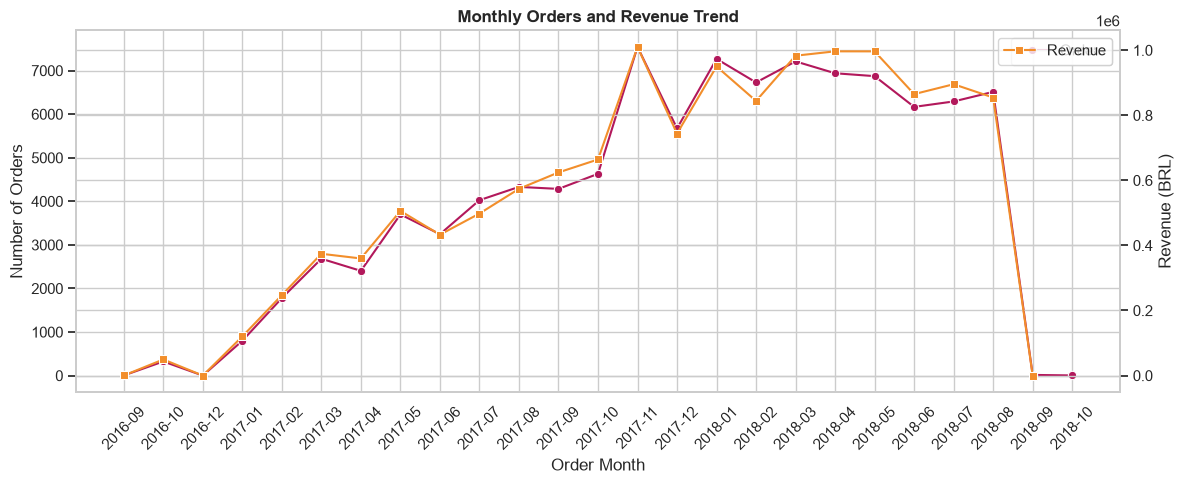

In [40]:
# Monthly orders
monthly_orders = (
    orders_analysis.dropna(subset=["order_purchase_timestamp"])
    .assign(
        order_month=lambda x:
            x["order_purchase_timestamp"].dt.to_period("M")
    )
    .groupby("order_month")["order_id"]
    .nunique()
    .rename("total_orders")
)

# Monthly revenue from item prices
monthly_revenue = (
    items_analysis.dropna(subset=["order_purchase_timestamp"])
    .assign(
        order_month=lambda x:
            x["order_purchase_timestamp"].dt.to_period("M")
    )
    .groupby("order_month")["price"]
    .sum(min_count=1)
    .rename("revenue_brl")
)

monthly = pd.concat(
    [monthly_orders, monthly_revenue], axis=1
).sort_index()

monthly.index = monthly.index.astype(str)

fig, ax1 = plt.subplots(figsize=(12, 5))

sns.lineplot(
    x=monthly.index, y=monthly["total_orders"],
    marker="o", ax=ax1, color="#b2185b",
    label="Orders"
)
ax1.set_ylabel("Number of Orders")
ax1.set_xlabel("Order Month")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
sns.lineplot(
    x=monthly.index, y=monthly["revenue_brl"],
    marker="s", ax=ax2, color="#f28e2b",
    label="Revenue"
)
ax2.set_ylabel("Revenue (BRL)")

ax1.set_title("Monthly Orders and Revenue Trend")
fig.tight_layout()
plt.show()

### Business Insight & Recommendation — Monthly Trend Chart

Compare the order and revenue lines together. If revenue rises faster than order volume, investigate whether order values increased; if orders rise but revenue does not keep pace, review basket value and product mix. Use recurring peaks to plan inventory and campaign timing, and verify whether any apparent spike is caused by an unusually small comparison month.

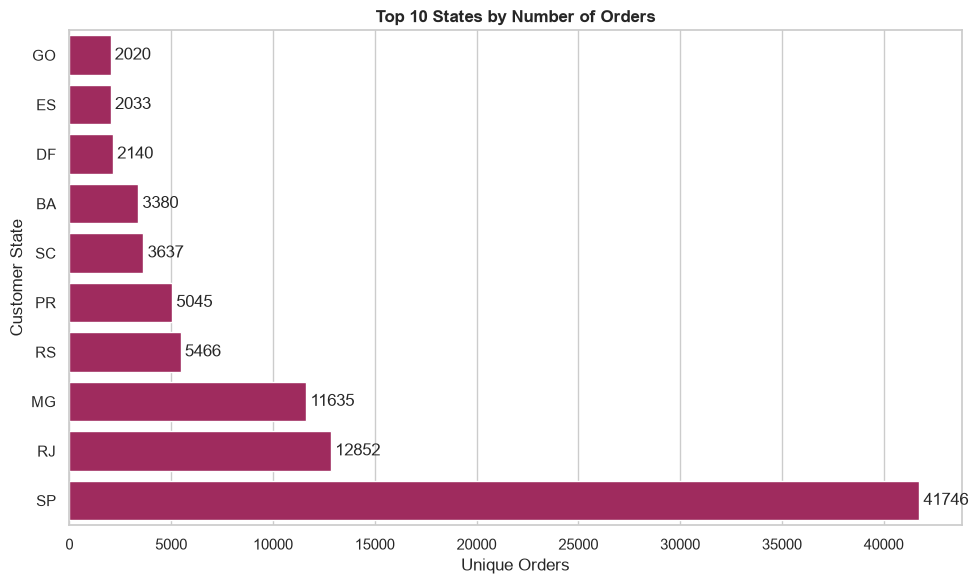

In [41]:
state_orders = (
    orders_analysis.groupby("customer_state")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=state_orders.values,
    y=state_orders.index,
    color="#b2185b"
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.title("Top 10 States by Number of Orders")
plt.xlabel("Unique Orders")
plt.ylabel("Customer State")
plt.tight_layout()
plt.show()

### Business Insight & Recommendation — Top States by Orders

Use the highest-volume states to prioritize fulfilment capacity and customer-service coverage. Compare this chart with state-level cancellation and delivery results before allocating more budget: high demand is most valuable when service quality and unit economics are also healthy.

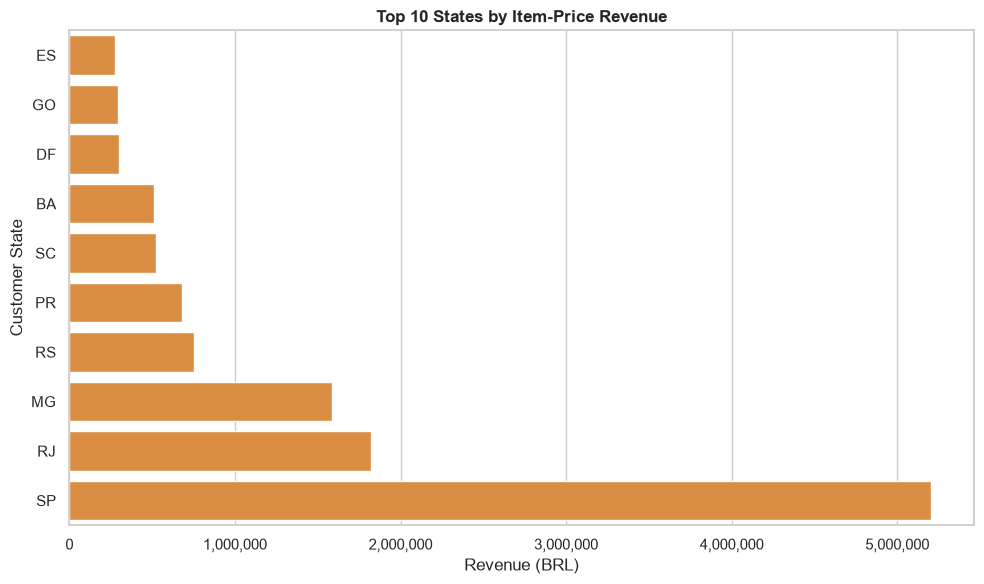

In [42]:
state_revenue = (
    items_analysis.groupby("customer_state")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=state_revenue.values,
    y=state_revenue.index,
    color="#f28e2b"
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)
plt.title("Top 10 States by Item-Price Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Customer State")
plt.tight_layout()
plt.show()

### Business Insight & Recommendation — Top States by Item-price Revenue

Revenue concentration can help guide regional merchandising and marketing tests. Before increasing spend in a high-revenue state, compare order count, average order value, freight burden, cancellations, and delivery reliability; revenue alone does not show profitability.

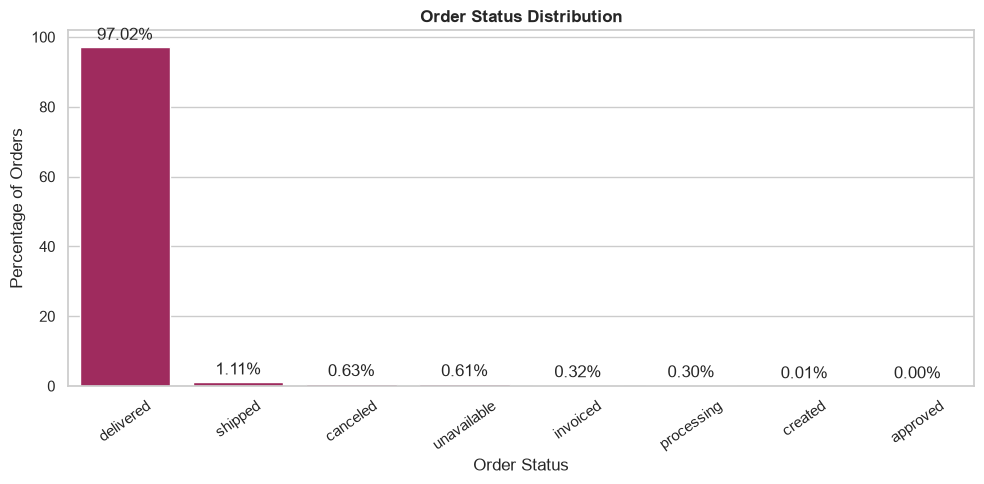

In [43]:
status_pct = (
    orders_analysis["order_status"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=status_pct.index,
    y=status_pct.values,
    color="#b2185b"
)

ax.bar_label(
    ax.containers[0],
    labels=[f"{v:.2f}%" for v in status_pct.values],
    padding=3
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Percentage of Orders")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

### Business Insight & Recommendation — Order Status Distribution

Use the status mix as an operational health check. Investigate the cancelled share and any large non-delivered statuses, then review whether issues are concentrated by month, seller, or region. Status categories describe the order lifecycle, so they should not all be interpreted as failures.

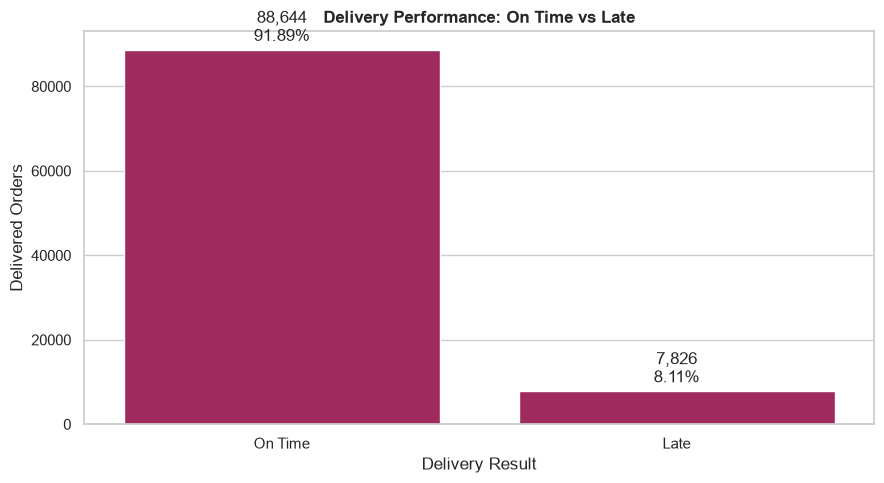

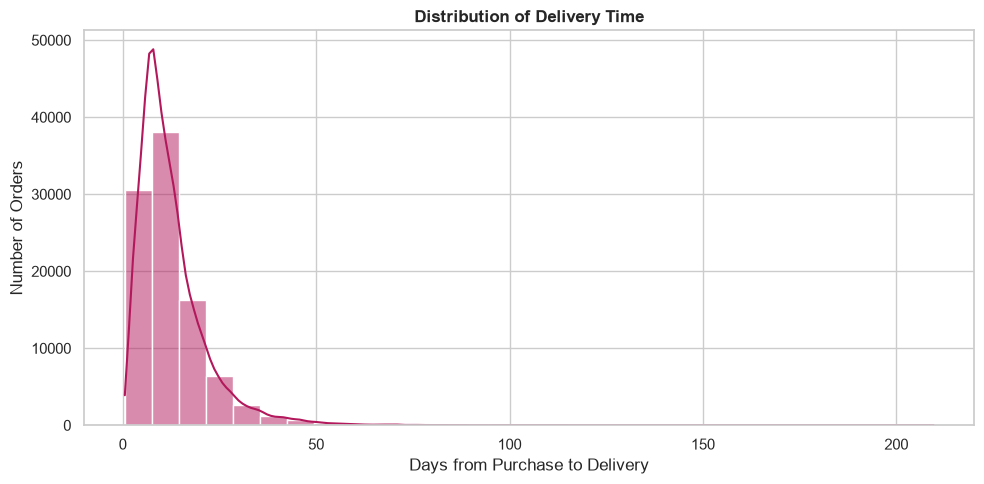

Average delivery days: 12.56
Median delivery days: 10.22
Late delivery rate: 8.11%


In [44]:
delivered = orders_analysis[
    (orders_analysis["order_status"] == "delivered")
    & orders_analysis["order_delivered_customer_date"].notna()
    & orders_analysis["order_purchase_timestamp"].notna()
    & orders_analysis["order_estimated_delivery_date"].notna()
].copy()

delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivered["delay_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivered["delivery_result"] = np.where(
    delivered["delay_days"] > 0, "Late", "On Time"
)

plt.figure(figsize=(9, 5))
ax = sns.countplot(
    data=delivered,
    x="delivery_result",
    order=["On Time", "Late"],
    color="#b2185b"
)

total = len(delivered)

for container in ax.containers:
    labels = [
        f"{int(v):,}\n{v / total:.2%}"
        for v in container.datavalues
    ]
    ax.bar_label(container, labels=labels, padding=3)

plt.title("Delivery Performance: On Time vs Late")
plt.xlabel("Delivery Result")
plt.ylabel("Delivered Orders")
plt.tight_layout()
plt.show()

# Delivery time distribution
plt.figure(figsize=(10, 5))
sns.histplot(
    data=delivered,
    x="delivery_days",
    bins=30,
    kde=True,
    color="#b2185b"
)
plt.title("Distribution of Delivery Time")
plt.xlabel("Days from Purchase to Delivery")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

print("Average delivery days:",
      round(delivered["delivery_days"].mean(), 2))
print("Median delivery days:",
      round(delivered["delivery_days"].median(), 2))
print("Late delivery rate:",
      f"{(delivered['delivery_result'].eq('Late').mean() * 100):.2f}%")

### Business Insight & Recommendation — Delivery Reliability

The reported **91.89% on-time delivery rate** suggests most eligible delivered orders met their estimated date, but the late-delivery segment still deserves investigation. Segment late orders by state and seller, and focus on recurring causes rather than treating every delay as the same problem. The **12.56-day average purchase-to-delivery window** can also inform customer-facing delivery expectations.

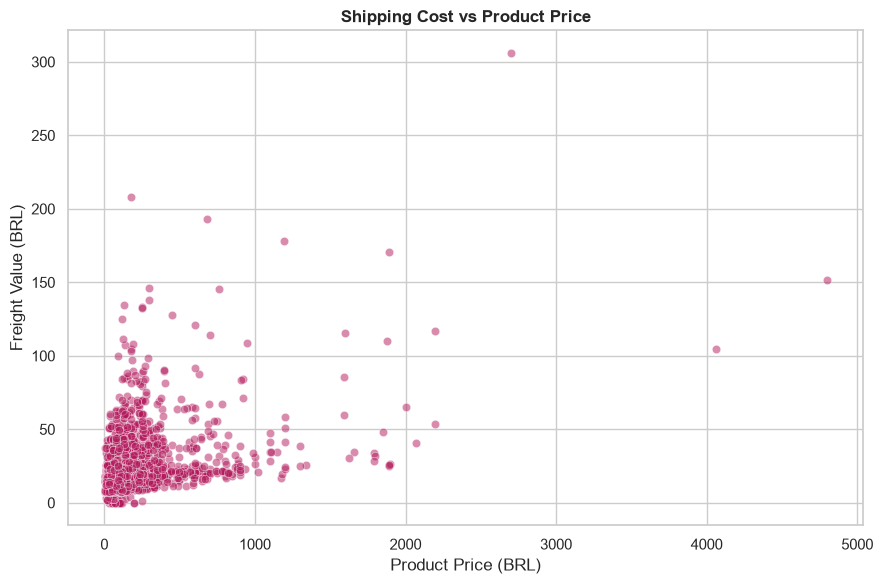

Average freight charge (BRL): 19.99
Median freight as % of item price: 23.14%


In [45]:
shipping_data = items_analysis.dropna(
    subset=["price", "freight_value"]
).copy()

# Sample only for faster plotting if the dataset is large
shipping_sample = shipping_data.sample(
    n=min(5000, len(shipping_data)),
    random_state=42
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=shipping_sample,
    x="price",
    y="freight_value",
    alpha=0.5,
    color="#b2185b"
)

plt.title("Shipping Cost vs Product Price")
plt.xlabel("Product Price (BRL)")
plt.ylabel("Freight Value (BRL)")
plt.tight_layout()
plt.show()

shipping_data["freight_pct"] = np.where(
    shipping_data["price"] > 0,
    shipping_data["freight_value"] / shipping_data["price"] * 100,
    np.nan
)

print("Average freight charge (BRL):",
      round(shipping_data["freight_value"].mean(), 2))
print("Median freight as % of item price:",
      f"{shipping_data['freight_pct'].median():.2f}%")

### Business Insight & Recommendation — Shipping Cost vs Product Price

Look for items where freight is large relative to item price, rather than assuming that expensive products always have expensive shipping. Review outliers by seller and destination and test whether bundling, packaging changes, or carrier negotiations could improve the customer experience without eroding margins. This chart shows association, not causation.

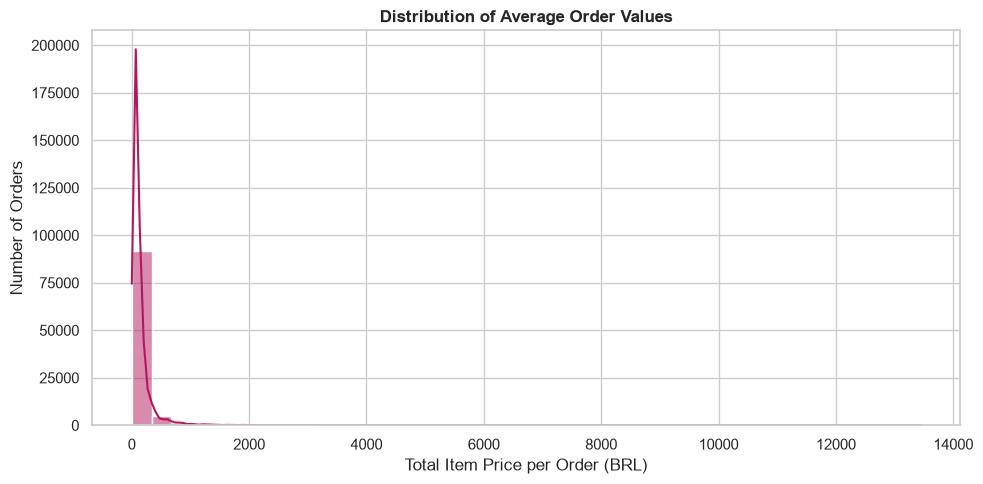

Average Order Value (BRL): 137.75
Median Order Value (BRL): 86.90


In [57]:
order_values = (
    df_order_item.groupby("order_id")["price"]
    .sum()
    .rename("order_value_brl")
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=order_values,
    x="order_value_brl",
    bins=40,
    kde=True,
    color="#b2185b"
)

plt.title("Distribution of Average Order Values")
plt.xlabel("Total Item Price per Order (BRL)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

print("Average Order Value (BRL):",
      f"{order_values['order_value_brl'].mean():,.2f}")
print("Median Order Value (BRL):",
      f"{order_values['order_value_brl'].median():,.2f}")

### Business Insight & Recommendation — Order Value Distribution

Use the distribution to understand whether most orders cluster around a typical basket value or whether a small number of large orders pull up the average. The **137.75 BRL AOV** is a useful baseline for testing bundles and cross-sell ideas; track contribution margin as well as AOV to ensure promotions create value.

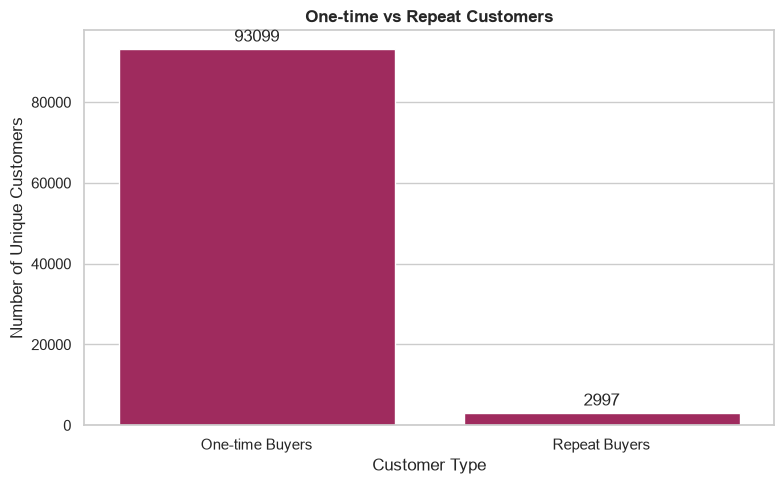

Repeat customer rate: 3.12%


In [58]:
customer_orders = (
    orders_analysis.groupby("customer_unique_id")["order_id"]
    .nunique()
)

repeat_summary = pd.Series({
    "One-time Buyers": (customer_orders == 1).sum(),
    "Repeat Buyers": (customer_orders > 1).sum()
})

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=repeat_summary.index,
    y=repeat_summary.values,
    color="#b2185b"
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.title("One-time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Unique Customers")
plt.tight_layout()
plt.show()

repeat_rate = (customer_orders > 1).mean() * 100
print("Repeat customer rate:", f"{repeat_rate:.2f}%")

### Business Insight & Recommendation — One-time vs Repeat Customers

The **3.12% repeat-customer rate** indicates that repeat purchasing is uncommon within the observed dataset window. Consider testing post-purchase engagement, replenishment reminders where relevant, loyalty incentives, and personalized recommendations. Measure whether these actions increase second purchases over time rather than assuming low repeat rate has a single cause.

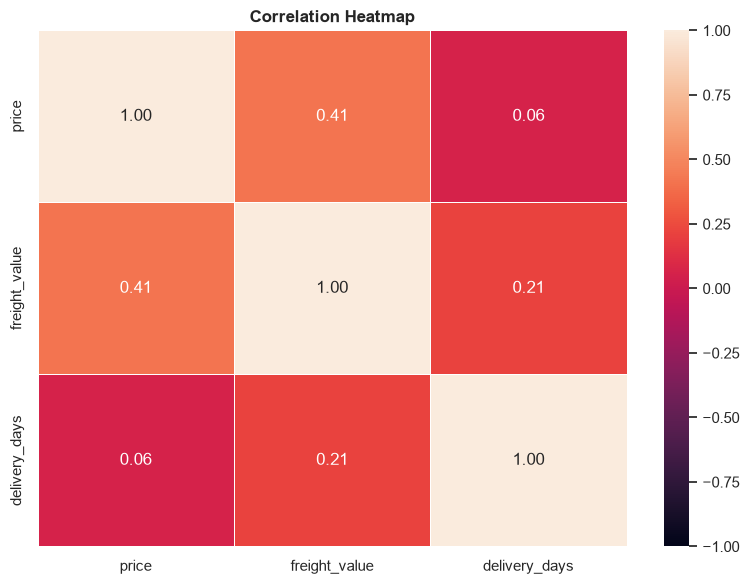

In [59]:
corr_data = items_analysis[
    ["price", "freight_value"]
].copy()

corr_data["delivery_days"] = np.nan

# Add delivery time to item rows using order-level data
delivery_lookup = (
    delivered.set_index("order_id")["delivery_days"]
)

corr_data["delivery_days"] = (
    items_analysis["order_id"].map(delivery_lookup)
)

corr_matrix = corr_data.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="rocket",
    fmt=".2f",
    linewidths=0.5,
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Business Insight & Recommendation — Correlation Heatmap

Use the heatmap to spot variables that move together, then investigate whether the relationship is operationally meaningful. Correlation does not establish causation. Also note that delivery time is attached to item-level rows, so orders containing multiple items appear multiple times; for a more rigorous relationship analysis, calculate correlations at a consistent grain (for example, one row per order) before drawing strong conclusions.